<h1>EDA</h1>

In [3]:
import pandas as pd
data = pd.read_csv('Intel_forecasting_data.csv')
data.describe()

,Generation,ASP Group,Week,Forecasted Demand,Customer Orders
count,26114.000000,26114.000000,26114.000000,2.611400e+04,26114.000000
mean,3.173508,10.658229,98.097381,3.902315e+04,12324.722180
std,0.941168,5.240162,50.980936,8.262289e+04,21509.126255
min,1.000000,1.000000,1.000000,0.000000e+00,16.000000
25%,2.000000,7.000000,57.000000,1.592000e+03,1035.000000
50%,3.000000,12.000000,98.000000,9.076000e+03,4299.000000
75%,4.000000,14.000000,139.750000,3.564900e+04,14013.000000
max,5.000000,22.000000,187.000000,1.150510e+06,381369.000000


In [4]:
data['SKU'].value_counts()

SKU
SKU-F-3    621
SKU-B-3    575
SKU-C-3    570
SKU-Q-3    567
SKU-K-3    564
          ... 
SKU-G-5     32
SKU-Q-1     31
SKU-Y-5     25
SKU-B-1     24
SKU-L-1     20
Name: count, Length: 86, dtype: int64

Woking with 86 unique SKUs over 187 weeks

<Axes: xlabel='SKU'>

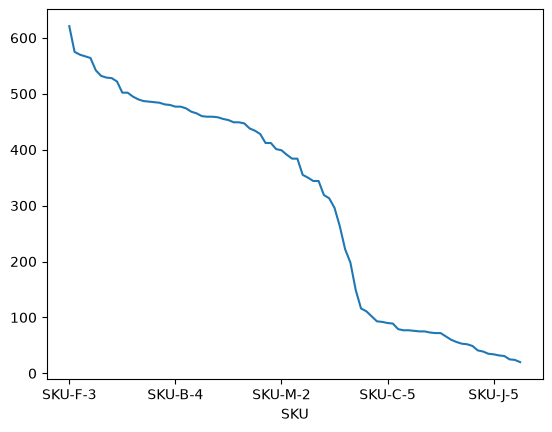

In [18]:
data['SKU'].value_counts().plot()

This is interesting, most SKUs are not offered (or ordered) for the whole period. 

<Axes: xlabel='SKU'>

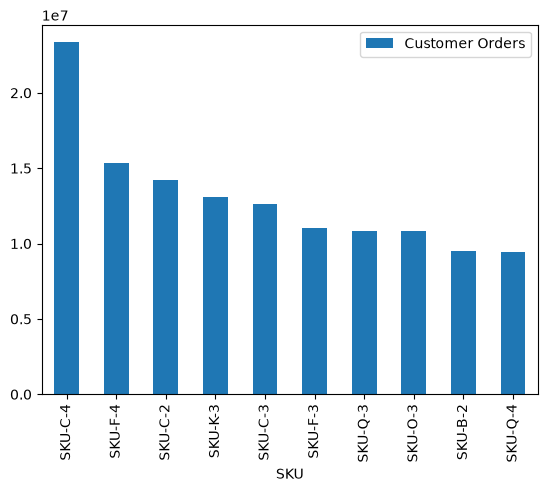

In [15]:
data[['SKU','Customer Orders']].groupby('SKU').sum().sort_values('Customer Orders', ascending = False).head(10).plot(kind = 'bar')

In [16]:
data.loc[data['SKU'] == 'SKU-C-4', 'Week'].min()

np.int64(75)

We don't see this product untill week 75 and it accounts for a large portion of demand, we can assume its a leading edge chip that was released in the middle of the period. We will defninitly inclue this SKU in our analysis

In [56]:
included_skus = ['SKU-C-4']

Now, lets find an SKU that is towads EOL and work our way inwards

<Axes: xlabel='SKU'>

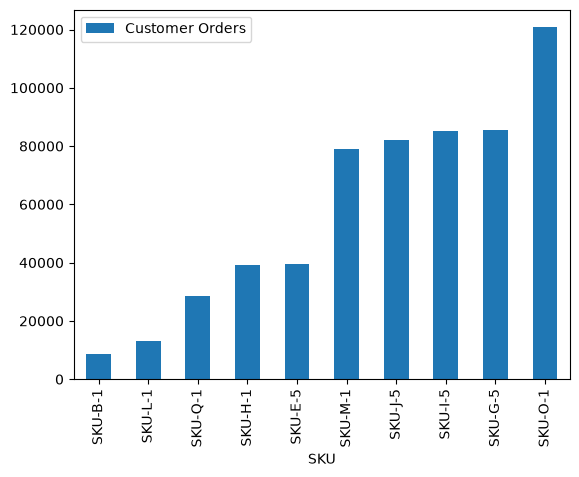

In [20]:
data[['SKU','Customer Orders']].groupby('SKU').sum().sort_values('Customer Orders').head(10).plot(kind = 'bar')

In [ ]:
eol_skus = data[['SKU','Customer Orders']].groupby('SKU').sum().sort_values('Customer Orders').head(10)
eol_skus_inds = [sku for sku in eol_skus.index]
data.loc[data['SKU'].isin(eol_skus_inds), ['SKU', 'Week']].groupby('SKU').count()

pd.concat([week_counts, eol_skus], axis = 1).sort_values('Customer Orders')

,Week,Customer Orders
SKU,,
SKU-B-1,24,8771
SKU-L-1,20,13119
SKU-Q-1,31,28517
SKU-H-1,41,39123
SKU-E-5,35,39486
SKU-M-1,56,78850
SKU-J-5,34,81941
SKU-I-5,39,85201
SKU-G-5,32,85476


SKU H-1 seems to be in enough weeks to make it worth it, lets pick up that one as well

In [57]:
included_skus.append('SKU-H-1')

For the remaining 3 SKUs, we will sort the data by average demand per week then choose the Q1, Q2, and Q3.

In [59]:
avg_demand_data = data[['SKU','Week', 'Customer Orders']].groupby('SKU').agg(
    avg_demand = ('Customer Orders', 'mean')
)
quants = avg_demand_data.quantile([.25,.5,.75], interpolation= 'nearest') #need to go back and find quantile indicies ugh

quant_skus = avg_demand_data.loc[avg_demand_data['avg_demand'].isin(quants['avg_demand'])]
included_skus.extend(quant_skus.index.to_list())
quant_skus

,avg_demand
SKU,
SKU-B-3,13963.304348
SKU-N-4,7011.743929
SKU-T-4,3734.613372


In [60]:
print(included_skus)

['SKU-C-4', 'SKU-H-1', 'SKU-B-3', 'SKU-N-4', 'SKU-T-4']
